# 08 · End-to-end performance: old machine vs. RTX 5070

**Process.** The full content pipeline runs six tools per episode, each as an `arq` job. The jobs
share one GPU behind a lock: transcription, diarization, chapters, relevance (the teacher), show
notes and shorts. Two benchmark runs were recorded with `scripts/run_pipeline.py`, which uploads
episodes, triggers every tool and logs each job's duration:

- **M9 season run** (old machine, 2026-10-16): the whole first season, 28 episodes. It found five
  integration bugs that only appear at scale.
- **RTX 5070 runs** (2026-11-07), on five episodes of the same season:
  - run A: the old M9 settings, transcription and diarization only;
  - run B: the final settings, all six tools.

| | |
|---|---|
| Report | §4 *End-to-End Performance* (Table "Processing time per job") |
| Data | `experiments/m9-perf/season1_run.csv`, `season1_shorts_rerun.csv`, `experiments/hw-upgrade/runA_m9_settings.csv`, `runB_final.csv` |
| Decisions | 0014 (M9 performance and hardening), 0016 (RTX 5070 pass) |

The CSVs are in the repository, so this notebook needs nothing else except the episode durations
from the database. Episodes are identified by their season code (1X09…), as in the CSV files.

In [1]:
from yts_nb import *

PERF = EXPERIMENTS / "m9-perf"
HW = EXPERIMENTS / "hw-upgrade"


def load(path):
    d = pd.read_csv(path)
    d["ep"] = d.episode.str.extract(r"(\dX\d\d)")[0]
    d["finished_at"] = pd.to_datetime(d.finished_at)
    return d.drop(columns="episode")


old = load(PERF / "season1_run.csv")
old_shorts = load(PERF / "season1_shorts_rerun.csv")
run_a = load(HW / "runA_m9_settings.csv")
run_b = load(HW / "runB_final.csv")
print({name: (len(d), d.status.value_counts().to_dict()) for name, d in
       [("M9 season", old), ("M9 shorts rerun", old_shorts), ("5070 run A", run_a), ("5070 run B", run_b)]})

{'M9 season': (171, {'succeeded': 168, 'failed': 3}), 'M9 shorts rerun': (28, {'succeeded': 28}), '5070 run A': (10, {'succeeded': 10}), '5070 run B': (30, {'succeeded': 30})}


Three jobs failed in the M9 season run. These were the integration bugs, later fixed. After the
fix, Shorts was re-rendered for the whole season (`season1_shorts_rerun.csv`). The table uses the
original run's times, as the report does, and takes the re-run's value only where the original
job failed.

In [2]:
print(old[old.status == "failed"][["ep", "tool"]].to_string(index=False))

# Durations come from the database, matched by season code: upload ids differ between runs.
uploads = await sql("select filename, duration_seconds from uploads")
uploads["ep"] = uploads.filename.str.extract(r"(\dX\d\d)")[0]
dur = uploads.dropna(subset=["ep"]).groupby("ep").duration_seconds.first()
minutes = (dur[sorted(run_b.ep.unique())] / 60).rename("minutes")

tools = ["transcribe", "diarize", "chapters", "relevance", "shownotes", "shorts"]
old_p = old[old.status == "succeeded"].pivot_table(index="ep", columns="tool", values="seconds", aggfunc="last")
old_p = old_p.combine_first(old_shorts.pivot_table(index="ep", columns="tool", values="seconds", aggfunc="last"))
new_p = run_b.pivot_table(index="ep", columns="tool", values="seconds", aggfunc="last")
eps = minutes.sort_values().index


def r0(x):
    """Round half up, as printed in the report (Python's round() rounds half to even)."""
    return int(np.floor(x + 0.5))


table = pd.DataFrame({f"{minutes[e]:.1f} min": [f"{r0(old_p.loc[e, t])} → {r0(new_p.loc[e, t])}" for t in tools]
                      for e in eps}, index=tools)
table

  ep       tool
1X03 transcribe
1X30     shorts
1X30     shorts


,14.9 min,26.6 min,30.7 min,34.1 min,43.3 min
transcribe,67 → 24,93 → 42,87 → 51,259 → 60,206 → 51
diarize,140 → 34,89 → 68,177 → 31,297 → 66,146 → 40
chapters,45 → 57,224 → 40,43 → 64,129 → 109,233 → 67
relevance,320 → 77,363 → 54,402 → 98,352 → 127,494 → 101
shownotes,371 → 110,177 → 52,368 → 105,231 → 74,309 → 86
shorts,38 → 28,42 → 42,49 → 46,73 → 45,54 → 41


**Check against the report.** The report's table rounds each value to whole seconds. The cell
below compares all 60 numbers.

In [3]:
report = {  # tool: [(old, new) per episode, in increasing length]
    "transcribe": [(67, 24), (93, 42), (87, 51), (259, 60), (206, 51)],
    "diarize": [(140, 34), (89, 68), (177, 31), (297, 66), (146, 40)],
    "chapters": [(45, 57), (224, 40), (43, 64), (129, 109), (233, 67)],
    "relevance": [(320, 77), (363, 54), (402, 98), (352, 127), (494, 101)],
    "shownotes": [(371, 110), (177, 52), (368, 105), (231, 74), (309, 86)],
    "shorts": [(38, 28), (42, 42), (49, 46), (73, 45), (54, 41)],
}
mismatch = []
for t, pairs in report.items():
    for e, (o, n) in zip(eps, pairs):
        got = (r0(old_p.loc[e, t]), r0(new_p.loc[e, t]))
        mismatch += [(t, e, which, g, w) for which, g, w in zip(("old", "new"), got, (o, n)) if g != w]
print(f"{60 - len(mismatch)} of 60 values match the report")
for m in mismatch:
    print("  differs:", m)

60 of 60 values match the report


## Total wall time

Per-job times include the wait for the GPU lock while the other episode's jobs run, because two
episodes ran in parallel. They cannot be summed. The relevant figure is the wall time of the
whole run: from the start of its first job to the end of its last.

In [4]:
def wall(d):
    start = (d.finished_at - pd.to_timedelta(d.seconds, unit="s")).min()
    return (d.finished_at.max() - start).total_seconds()


audio_new = minutes.sum() * 60
w_new = wall(run_b)
print(f"RTX 5070, run B: {len(minutes)} episodes, {audio_new / 3600:.2f} h of audio in {w_new / 3600:.2f} h "
      f"-> {w_new / audio_new:.2f} × real time")
print(compare("new machine, × real time", w_new / audio_new, 0.12, tol=0.005))

old_eps = sorted(old.ep.unique())
audio_old = dur.reindex(old_eps).sum()
w_old = wall(old)
print(f"\nold machine, M9: {len(old_eps)} episodes ({dur.reindex(old_eps).notna().sum()} with a duration in the DB), "
      f"{audio_old / 3600:.1f} h of audio; first job start to last job end: {w_old / 3600:.2f} h "
      f"-> {w_old / audio_old:.2f} × real time")

# Idle stretches: time between one job's end and the next job's start, over the whole run.
spans = sorted(zip(old.finished_at - pd.to_timedelta(old.seconds, unit="s"), old.finished_at))
busy_until, idle = spans[0][1], []
for s, f in spans[1:]:
    if s > busy_until:
        idle.append(((s - busy_until).total_seconds(), busy_until))
    busy_until = max(busy_until, f)
idle.sort(reverse=True)
print("longest idle stretches in the M9 run:", [(f"{g / 60:.0f} min", f"{t:%H:%M}") for g, t in idle[:3]])
print(f"busy time (wall time minus idle stretches): {(w_old - sum(g for g, _ in idle)) / 3600:.2f} h")
print("recorded in decision 0014: 15.1 h of audio in 4.6 h, 0.30 × real time")

RTX 5070, run B: 5 episodes, 2.49 h of audio in 0.31 h -> 0.12 × real time
new machine, × real time: recomputed 0.1242 matches the report (0.1200)

old machine, M9: 28 episodes (28 with a duration in the DB), 15.1 h of audio; first job start to last job end: 5.06 h -> 0.33 × real time
longest idle stretches in the M9 run: [('4 min', '00:15'), ('4 min', '19:35'), ('1 min', '00:14')]
busy time (wall time minus idle stretches): 4.92 h
recorded in decision 0014: 15.1 h of audio in 4.6 h, 0.30 × real time


**Discrepancy.** The audio total matches the record (15.1 h), but the wall time does not.
- From the CSV, the M9 run took **5.06 h** from its first job's start to its last job's end, i.e.
  **0.33 × real time**. Decision 0014 and the report give 4.6 h and 0.30 ×.
- No reasonable definition reproduces 4.6 h from the CSV. Stopping at the last successful job,
  leaving out the failed and retried Shorts jobs, or removing the idle stretches all give 4.9–5.1 h.
- The terminal output of that night was not kept, so the source of the recorded figure cannot be
  checked. **The reproducible value is the one computed here.** It does not change the comparison:
  the RTX 5070 is still more than twice as fast end to end, with larger models.

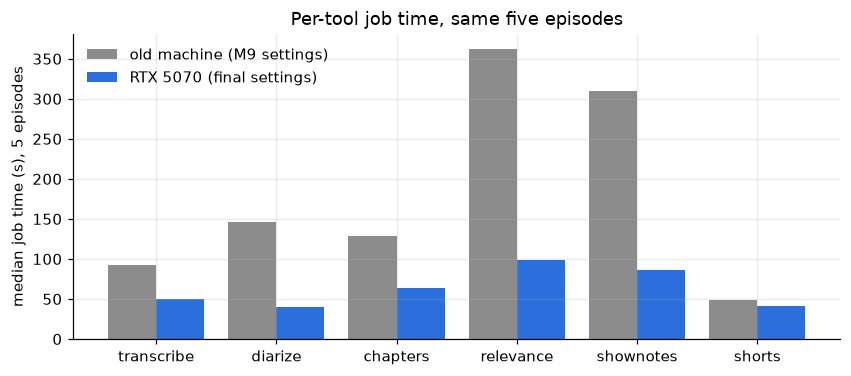

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(tools))
o = [old_p.loc[eps, t].median() for t in tools]
n = [new_p.loc[eps, t].median() for t in tools]
ax.bar(x - 0.2, o, 0.4, color=GREY, label="old machine (M9 settings)")
ax.bar(x + 0.2, n, 0.4, color=COLORS[0], label="RTX 5070 (final settings)")
ax.set_xticks(x, tools)
ax.set(ylabel="median job time (s), 5 episodes", title="Per-tool job time, same five episodes")
ax.legend(frameon=False)
plt.show()

## Same settings, new GPU (run A)

Run A kept the old M9 settings on the new GPU (`turbo` Whisper and a diarization batch of 8). It
separates the effect of the hardware from that of the new settings.

In [6]:
a = run_a.pivot_table(index="ep", columns="tool", values="seconds", aggfunc="last")
cmp = pd.DataFrame({
    "old machine, M9 settings": old_p.loc[a.index, ["transcribe", "diarize"]].median(),
    "RTX 5070, M9 settings (run A)": a[["transcribe", "diarize"]].median(),
    "RTX 5070, final settings (run B)": new_p.loc[a.index, ["transcribe", "diarize"]].median(),
}).round(1)
cmp

,"old machine, M9 settings","RTX 5070, M9 settings (run A)","RTX 5070, final settings (run B)"
tool,,,
transcribe,92.6,41.6,50.6
diarize,146.1,45.9,39.7


## Summary

- All 60 per-job values of the report's table are reproduced from the CSVs.
- On the RTX 5070, all six tools processed 2.5 h of audio in about 0.31 h, about 0.12 × real
  time. The M9 season run on the old machine took 0.33 × real time by its CSV; 0.30 × was recorded.
- The new machine runs larger and more accurate models (`large-v3` instead of `turbo`, a 9B LLM
  instead of a 4B), and is still several times faster.
- Chapters did not always get faster, because the final settings also generate titles with the 9B
  model, which must be loaded for each job.
- The relevance times are the teacher's. The live BiLSTM student scores an episode in about a
  second (notebook 03).